## Integrating proteomic data into mitoMammal using EFLUX

In [14]:
import cobra
print(cobra.Configuration().solver)

<module 'optlang.glpk_interface' from 'c:\\Users\\cayle\\miniconda3\\envs\\mitomammal\\lib\\site-packages\\optlang\\glpk_interface.py'>


In [15]:
# Anywhere there is "###" indicates that I have either changed 
# or added code to the default notebook in the forthcoming lines of code
# I have commented out all BAT simulations, and 
# will run those in a separate notebook. 

In [16]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import math
import cobra
import os
from os.path import join
from cobra.util import create_stoichiometric_matrix
from cobra.util.solver import linear_reaction_coefficients
from cobra.io import read_sbml_model, write_sbml_model
from cobra.flux_analysis import pfba
from time import sleep
from cobra.flux_analysis import flux_variability_analysis
from efflux_method import *
###
#Running in the Python 3.8.20 Kernel 
#Made sure that efflux.py in same file as this notebook!
import matplotlib.colors as mcolors
import matplotlib.cm as cm


In [17]:
###
print(cobra.Configuration().solver)
#Checking that simualtion is using GLPK solver


<module 'optlang.glpk_interface' from 'c:\\Users\\cayle\\miniconda3\\envs\\mitomammal\\lib\\site-packages\\optlang\\glpk_interface.py'>


In [18]:
#please ensure you check the path of your machine is ponting to the data directory from the source file 
data_dir= (r"C:\Users\cayle\OneDrive\Documents\MitoMammal Author Data")

In [19]:
model = cobra.io.read_sbml_model(join(r"C:\Users\cayle\OneDrive\Documents\MitoMammal Author Data\6_universal_mito_model.xml")) 
list_of_genes=[] 
for gene in model.genes:
    list_of_genes.append(gene.id)
      #copied path from the MitoMammal model. 

In [20]:
###
# I want to check compartments in the model.
print("Compartments in the model:")
for compartment_id, compartment_name in model.compartments.items():
    print(f"  ID: {compartment_id} | Name: {compartment_name}")

Compartments in the model:
  ID: Cytosol | Name: Cytosol
  ID: Mitochondrion | Name: Mitochondrion
  ID: external | Name: External


## Constrain the model

In [21]:
def perform_FBA(file_path,id_gene,id_value,human,constant,objective_id):
    """This function open the model, constrain it with Omics data (human or not) and optimise the model with the selected objective function
    args:
        file_path (str):
        id_gene (int): position of the gene identifier in the dataframe
        id_value (int): position of the value in the dataframe
        human (bool): constrain data on humain or mouse data
        constant (int): constant value used to scale the constrain (only to make the value easier for human)
        objective_id (id): identifier of the objective function in the model
    return:
        model (cobra.core.model): a constrained model
        pfba (cobra.Solution.solution): solution of parsimonious FBA
    """
    ###
    model = cobra.io.read_sbml_model(join(r"C:\Users\cayle\OneDrive\Documents\MitoMammal Author Data\6_universal_mito_model.xml")) 
    list_of_genes=[] 
    for gene in model.genes:
        list_of_genes.append(gene.id)
    data_dictionary = read_csv_data(path=file_path,
                                      list_of_genes=list_of_genes,
                                      id_gene=id_gene,
                                      id_val=id_value,
                                      sep="\t",
                                      head=True)
    #
    model.objective = model.reactions[objective_id] 
    Eflux(model,data_dictionary,constant,1, ignore_human= not human,ignore_mus=human)
    exch,const=0,0
    for react in model.reactions:
        if react.bounds[1] == constant:
            const+=1
        elif react.bounds[1] == 1000:
            exch+=1
    
    return [model,pfba(model)]

In [22]:
###
# Perform FBA on the constrained model for Heart
result_Heart = perform_FBA(r"C:\Users\cayle\OneDrive\Documents\MitoMammal Author Data\Heart_data (2).tsv",0,1,False,50,70)
#The numbers are the column indeces: (0) id_gene, (1) id_value, (False, we are only considering mouse rn) human, (scaling constant) constant, (Reaction index) objective_id):

In [23]:
#result_BAT = perform_FBA(r"C:\Users\cayle\OneDrive\Documents\MitoMammal Author Data\BAT_data (2).tsv",0,1,False,50,420)

In [24]:
###
#Confirming that reaction at index 70 is the correct  objective function for Heart
print(f"Reaction at index 70: {model.reactions[70].id}")
print(f"Reaction name: {model.reactions[70].name}")
print(f"Reaction equation: {model.reactions[70].reaction}")

Reaction at index 70: OF_ATP_mitoMap
Reaction name: R_OF_ATP_mitoMap Maximum ATP production (ATP hydrolysis)
Reaction equation: atp_c + h2o_c --> adp_c + biomass_c + h_c + pi_c


# printing how many reactions constrained by the proteomic data

###
c != 50, != 100 (Eflux scaled to some expression val)

e ==50 (Efflux hit maximum cap- highest expressed gene)

u == 1000 (Excluded by efflux entirely)

In [25]:
#model = result_BAT[0]
model = result_Heart[0]
c=0
e=0
for reaction in model.reactions:
    c+= reaction._upper_bound != 50.0 and reaction._upper_bound != 1000.0
    e+= reaction._upper_bound == 1000.0
u = len(model.reactions) - c - e
print(f"There are :{c} constrained reactions\n           {u} unconstrained reactions\n           {e} exchange reactions")

There are :330 constrained reactions
           158 unconstrained reactions
           72 exchange reactions


## Read the result

In [26]:
result_Heart[0].summary()



Metabolite,Reaction,Flux,C-Number,C-Flux
akg_e,EX_akg_e,15.53,5,89.76%
glc_D_e,EX_glc_D_e,0.7493,6,5.20%
gln_L_e,EX_gln_L_e,0.3004,5,1.74%
h2o_e,EX_h2o_e,7.311,0,0.00%
mal_L_e,EX_mal_L_e,0.4157,4,1.92%
o2_e,EX_o2_e,0.5468,0,0.00%
oaa_e,EX_oaa_e,0.3004,4,1.39%
Metabolite,Reaction,Flux,C-Number,C-Flux
ala_L_e,EX_ala_L_e,-0.3004,3,1.04%
biomass_e,EX_biomass_e,-10.73,0,0.00%


In [27]:
sol = result_Heart[0].optimize()

In [ ]:
result_Heart[1]
print(result_Heart[1].fluxes.to_string())

# Convert each value to a formatted string
formatted = result_Heart[1].fluxes.apply(lambda x: f"{x:.10f}")
print(formatted.to_string())

flux_table = formatted.reset_index()
flux_table.columns = ["Reaction", "Flux"]
save_path = r"C:\Users\cayle\OneDrive\Documents\MitoMammal Author Data"
# Display table

print(flux_table.to_string(index=False))
# Save to Excel file
flux_table.to_csv("Mouse.Cardiac.flux_table.csv", index=False)

In [ ]:
cardiac_uptake_metabolites = ['a-ketogluterate','glucose', 'glutamine', 'H20', 'malate', 'O2','oxaloacetate']
cardiac_uptake_flux = [
                       sol.fluxes["EX_akg_e"], 
                       sol.fluxes["EX_glc_D_e"], 
                       sol.fluxes["EX_gln_L_e"], 
                       sol.fluxes["EX_h2o_e"], 
                       sol.fluxes["EX_o2_e"], 
                       sol.fluxes["EX_oaa_e"]
                      ]


In [ ]:
cardiac_secretion_metabolites = ['alanine', 'citrate', 'CO2', 'H', 'isocitrate','lactate', 'NH4', 'succinate']
cardiac_secretion_flux = [
                           sol.fluxes["EX_ala_L_e"],
                           sol.fluxes["EX_cit_e"],
                           sol.fluxes["EX_co2_e"],
                           sol.fluxes["EX_h_e"],
                           sol.fluxes["EX_icit_e"],
                           sol.fluxes["EX_lac_L_e"],
                           sol.fluxes["EX_nh4_e"],
                           sol.fluxes["EX_succ_e"]
                         ]     

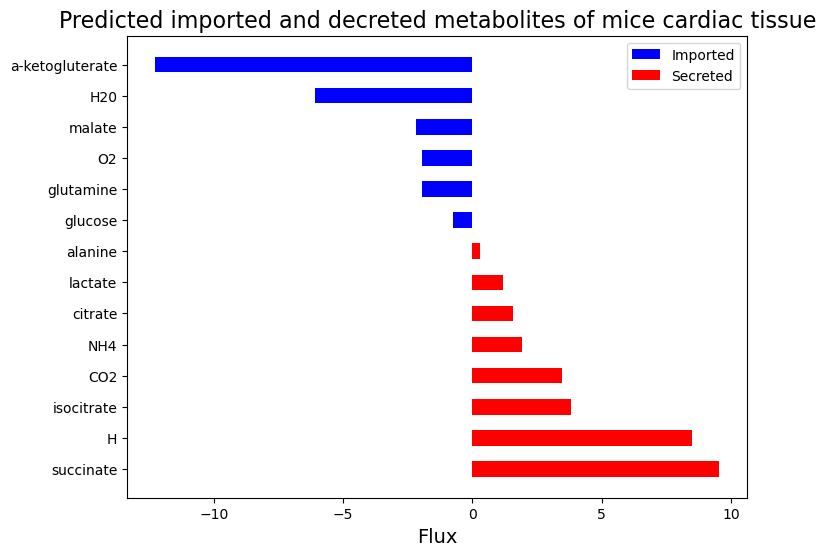

In [ ]:
#Code for graph from Authors
# Sort metabolites and fluxes based on flux values
sorted_uptake_metabolites, sorted_uptake_flux = zip(*sorted(zip(cardiac_uptake_metabolites, cardiac_uptake_flux), key=lambda x: x[1], reverse=True))
sorted_secretion_metabolites, sorted_secretion_flux = zip(*sorted(zip(cardiac_secretion_metabolites, cardiac_secretion_flux), key=lambda x: x[1], reverse=True))

# Create figure and axis objects
fig, ax = plt.subplots(figsize=(8, 6))  # Adjust the size as needed

# Plot secreted metabolites first
ax.barh(sorted_secretion_metabolites, sorted_secretion_flux, color='red', label='Secreted', height=0.5)

# Plot imported metabolites
ax.barh(sorted_uptake_metabolites, sorted_uptake_flux, color='blue', label='Imported', height=0.5)

# Add labels and title with increased font size
ax.set_xlabel('Flux', fontsize=14)  # Increase font size here
ax.set_title('Predicted imported and decreted metabolites of mice cardiac tissue', fontsize=16)  # Increase font size here

# Get the handles and labels of the legend
handles, labels = ax.get_legend_handles_labels()

# Reorder the handles and labels
handles = [handles[1], handles[0]]
labels = [labels[1], labels[0]]

# Create the legend with the reordered handles and labels
ax.legend(handles, labels)
# Save the figure as SVG
plt.savefig('mouse_cardiac_prot.svg', format='svg')
# Show plot
plt.show()

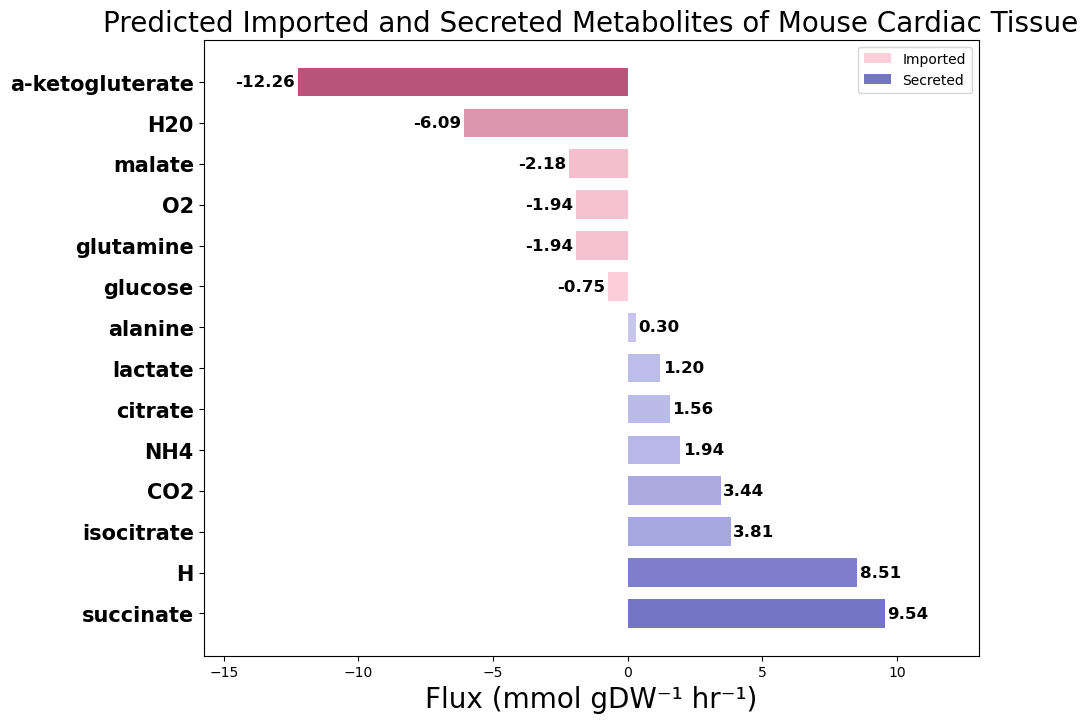

In [ ]:
### My graph
# Sort metabolites and fluxes based on flux values
sorted_uptake_metabolites, sorted_uptake_flux = zip(*sorted(zip(cardiac_uptake_metabolites, cardiac_uptake_flux), key=lambda x: x[1], reverse=True))
sorted_secretion_metabolites, sorted_secretion_flux = zip(*sorted(zip(cardiac_secretion_metabolites, cardiac_secretion_flux), key=lambda x: x[1], reverse=True))

fig, ax = plt.subplots(figsize=(10, 8)) 

uptake_norm = mcolors.Normalize(vmin=0, vmax=20)   
secretion_norm = mcolors.Normalize(vmin=0, vmax=20)   

uptake_cmap = mcolors.LinearSegmentedColormap.from_list('pink_ombre', ['#FFD6E0', '#8B0038'])
secretion_cmap = mcolors.LinearSegmentedColormap.from_list('blue_ombre', ['#C8C8F0', '#1A1A99'])

uptake_colors = [uptake_cmap(uptake_norm(abs(v))) for v in sorted_uptake_flux]
secretion_colors = [secretion_cmap(secretion_norm(abs(v))) for v in sorted_secretion_flux]

ax.barh(sorted_secretion_metabolites, sorted_secretion_flux, color=secretion_colors, label='Secreted', height=0.7)
ax.barh(sorted_uptake_metabolites, sorted_uptake_flux, color=uptake_colors, label='Imported', height=0.7)
from matplotlib.colorbar import ColorbarBase
import matplotlib.gridspec as gridspec

full_cmap = mcolors.LinearSegmentedColormap.from_list('full_ombre', [
    '#8B0038',   #dark pink (high uptake)
    '#FFD6E0',   #light pink
    '#E8D5F0',   #lilac transition
    '#C8C8F0',   #light blue
    '#1A1A99'    #dark blue (high secretion)
])

for metabolite, flux in zip(sorted_uptake_metabolites, sorted_uptake_flux):
    ax.text(flux - 0.1, metabolite, f'{flux:.2f}', va='center', ha='right', fontsize=12, fontweight= 'bold')

for metabolite, flux in zip(sorted_secretion_metabolites, sorted_secretion_flux):
    ax.text(flux + 0.1, metabolite, f'{flux:.2f}', va='center', ha='left', fontsize=12, fontweight= 'bold')

ax.set_xlabel('Flux (mmol gDW⁻¹ hr⁻¹)', fontsize=20) 
ax.set_title('Predicted Imported and Secreted Metabolites of Mouse Cardiac Tissue', fontsize=20)
ax.tick_params(axis='y', labelsize=15)
for tick in ax.get_yticklabels():
    tick.set_fontweight('bold')  

handles, labels = ax.get_legend_handles_labels()

#Reorder the handles and labels
handles = [handles[1], handles[0]]
labels = [labels[1], labels[0]]

#Create the legend with the reordered handles and labels
ax.legend(handles, labels)

sm = cm.ScalarMappable(cmap=full_cmap, norm=mcolors.Normalize(vmin=-50, vmax=50))
sm.set_array([])

# Expand x-axis limits to fit text labels that extend beyond bar tips
xmin, xmax = ax.get_xlim()
padding = (xmax - xmin) * 0.1  # 15% padding on each side
ax.set_xlim(xmin - padding, xmax + padding)
#cbar = plt.colorbar(sm, ax=ax, fraction=0.03, pad=0.02)
#cbar.set_label('flux', fontsize=10)
#cbar.set_ticks([-50, -25, -10, -1, 0, 1, 10, 25, 50])
#cbar.set_ticklabels(['-50', '-25', '-10', '-1', '0', '1', '10', '25', '50'])
plt.savefig('mouse_cardiac_prot.svg', format='svg')
# Show plot
plt.show()

In [ ]:
### Mitochondrial Involvement
def print_result(solution):
    print(f"OF value (ATP) :\t {solution[70]}")
    #print(f"OF value (UCP) :\t {solution[420]}")
    print(f"Complex I:\t{solution[107]}")
    print(f"Complex II:\t{solution[108]}")
    print(f"Complex III:\t{solution[109]}")
    print(f"Complex IV:\t{solution[110]}")
    print(f"Complex V:\t{solution[111]}")

In [ ]:
print_result(result_Heart[1])

OF value (ATP) :	 10.728046628471516
Complex I:	1.8078211381707405
Complex II:	-0.7160950609017798
Complex III:	1.0899182561307903
Complex IV:	0.544959128065395
Complex V:	0.4087193460490463


In [ ]:
###
model = result_Heart[0]   #The constrained model after efflux 
solution = result_Heart[1] #The pFBA solution for the constrained model

indices = [70, 107, 108, 109, 110, 111]
names = ["OF value", "Complex I", "Complex II", "Complex III", "Complex IV", "Complex V"]

for idx, name in zip(indices, names):
    rxn = model.reactions[idx]        #reaction object at the index           
    flux = solution.fluxes[rxn.id]     #The flux solution from pFBA           
    
    print(f"\n{'='*60}")
    print(f"{name} (index {idx})")
    print(f"Reaction ID: {rxn.id}")
    print(f"Reaction name: {rxn.name}")
    print(f"Flux value: {flux:.6f}")
    print(f"Reaction equation: {rxn.reaction}")
    print(f"Lower/upper bounds: {rxn.lower_bound} / {rxn.upper_bound}")
    
    #Consumed and Produced Metabolites
    substrates = [met for met, coeff in rxn.metabolites.items() if coeff < 0]
    products = [met for met, coeff in rxn.metabolites.items() if coeff > 0]
    
    print(f"Consumes (substrates): {', '.join([m.id for m in substrates])}")
    print(f"Produces (products): {', '.join([m.id for m in products])}")
    
    #Reactions that share metabolites with this reaction 
    interacting = set()
    for met in rxn.metabolites:
        for other_rxn in met.reactions:
            if other_rxn != rxn:
                interacting.add(other_rxn)
    
    print(f"Number of interacting reactions (share metabolites): {len(interacting)}")
   


OF value (index 70)
Reaction ID: OF_ATP_mitoMap
Reaction name: R_OF_ATP_mitoMap Maximum ATP production (ATP hydrolysis)
Flux value: 10.728047
Reaction equation: atp_c + h2o_c --> adp_c + biomass_c + h_c + pi_c
Lower/upper bounds: 0.0 / 1000.0
Consumes (substrates): h2o_c, atp_c
Produces (products): adp_c, pi_c, h_c, biomass_c
Number of interacting reactions (share metabolites): 175

Complex I (index 107)
Reaction ID: CI_mitoMap
Reaction name: R_CI_mitoMap NADH dehydrogenase
Flux value: 1.807821
Reaction equation: 3.996 PMF_m + h_m + nadh_m + 0.002 o2_m + 0.999 q10_m <=> 3.996 PMF_c + nad_m + 0.002 o2s_m + 0.999 q10h2_m
Lower/upper bounds: -2.452316076294278 / 2.452316076294278
Consumes (substrates): h_m, PMF_m, nadh_m, q10_m, o2_m
Produces (products): PMF_c, nad_m, q10h2_m, o2s_m
Number of interacting reactions (share metabolites): 138

Complex II (index 108)
Reaction ID: CII_mitoMap
Reaction name: R_CII_mitoMap succinate dehydrogenase
Flux value: -0.716095
Reaction equation: q10_m + 

In [ ]:
#print_result(result_BAT[1])

In [ ]:
#result_BAT[0].summary()

In [ ]:
#model_fbat = result_BAT[0]
#model_fbat.metabolites.h_m.summary(solution=result_BAT[1])

In [ ]:
#ETF fluxes - HEART
print(result_Heart[1].fluxes[143], model.reactions[143].id, model.reactions[143].reaction)
print(result_Heart[1].fluxes[149], model.reactions[149].id, model.reactions[149].reaction)
print(result_Heart[1].fluxes[154], model.reactions[154].id, model.reactions[154].reaction)
print(result_Heart[1].fluxes[159], model.reactions[159].id, model.reactions[159].reaction)
print(result_Heart[1].fluxes[164], model.reactions[164].id, model.reactions[164].reaction)
print(result_Heart[1].fluxes[169], model.reactions[169].id, model.reactions[169].reaction)
print(result_Heart[1].fluxes[212], model.reactions[212].id, model.reactions[212].reaction)
print(result_Heart[1].fluxes[227], model.reactions[227].id, model.reactions[227].reaction)
print(result_Heart[1].fluxes[263], model.reactions[263].id, model.reactions[263].reaction)
print(result_Heart[1].fluxes[282], model.reactions[282].id, model.reactions[282].reaction)

0.0 ACADLC16_mitoMap h2o_m + pmtcoa_m + q10_m --> 3hexdcoa_m + q10h2_m
0.0 r1447_mitoMap ddcacoa_m + q10_m --> dd2coa_m + q10h2_m
0.0 r1451 dcacoa_m + q10_m --> dc2coa_m + q10h2_m
0.0 r1448 occoa_m + q10_m --> HC01415_m + q10h2_m
0.0 r1450 HC01409_m + q10_m --> HC01410_m + q10h2_m
0.0 r1446 btcoa_m + q10_m --> b2coa_m + q10h2_m
0.0 r0655 ivcoa_m + q10_m --> 3mb2coa_m + q10h2_m
0.0 ACCOALm atp_m + coa_m + ppa_m --> amp_m + ppcoa_m + ppi_m
0.0 AMCOXO2_mitoMap amuco_c + h2o_c + h_c + nadh_c --> 2oxoadp_c + nad_c + nh4_c
0.0 PROD2mB_mitoMap pro_L_m + q10_m --> 1pyr5c_m + h_m + q10h2_m


In [ ]:
print(result_Heart[1].fluxes[105], model.reactions[105].id, model.reactions[105].reaction)
print(result_Heart[1].fluxes[100], model.reactions[100].id, model.reactions[100].reaction)
print(result_Heart[1].fluxes[180], model.reactions[180].id, model.reactions[180].reaction)
print(result_Heart[1].fluxes[106], model.reactions[106].id, model.reactions[106].reaction)
print(result_Heart[1].fluxes[104], model.reactions[104].id, model.reactions[104].reaction)
print(result_Heart[1].fluxes[163], model.reactions[163].id, model.reactions[163].reaction)
print(result_Heart[1].fluxes[102], model.reactions[102].id, model.reactions[102].reaction)
print(result_Heart[1].fluxes[44], model.reactions[44].id, model.reactions[44].reaction)
print(result_Heart[1].fluxes[66], model.reactions[66].id, model.reactions[66].reaction)
print(result_Heart[1].fluxes[77], model.reactions[77].id, model.reactions[77].reaction)
print(result_Heart[1].fluxes[88], model.reactions[88].id, model.reactions[88].reaction)

2.7982035842433826 FUMm fum_m + h2o_m <=> mal_L_m
0.0 ICDHxm icit_m + nad_m --> akg_m + co2_m + nadh_m
0.0 r0760 HC01588_c + h_c + malACP_c --> ACP_c + HC01589_c + co2_c
0.0 MDHm mal_L_m + nad_m <=> h_m + nadh_m + oaa_m
-8.820689680242634 SUCOASm atp_m + coa_m + succ_m <=> adp_m + pi_m + succoa_m
0.0 r0732 HC01406_m + coa_m <=> HC01409_m + accoa_m
8.820689680242635 AKGDm akg_m + coa_m + nad_m --> co2_m + nadh_m + succoa_m
0.0 EX_met_L_e met_L_e <=> 
0.0 EX_tyr_L_e tyr_L_e <=> 
0.7493188010899183 PFK atp_c + f6p_c --> adp_c + fdp_c + h_c
-1.1982223508672338 LDH_L lac_L_c + nad_c <=> h_c + nadh_c + pyr_c


In [ ]:
result_Heart[1]
print(result_Heart[1].fluxes.to_string())


EX_2hb_e                   0.000000e+00
EX_ac_e                    0.000000e+00
EX_acac_e                  0.000000e+00
EX_akg_e                  -1.553134e+01
EX_ala_B_e                 0.000000e+00
EX_ala_L_e                 3.004153e-01
EX_arg_L_e                 0.000000e+00
EX_argsuc_e                0.000000e+00
EX_asn_L_e                 0.000000e+00
EX_asp_L_e                 0.000000e+00
EX_bhb_e                   0.000000e+00
EX_bilirub_e               0.000000e+00
EX_biomass_e               1.072805e+01
EX_but_e                   0.000000e+00
EX_chol_e                  0.000000e+00
EX_cit_e                   1.561469e+00
EX_citr_L_e                0.000000e+00
EX_co_e                    0.000000e+00
EX_co2_e                   1.809629e+00
EX_creat_e                 0.000000e+00
EX_cyan_e                  0.000000e+00
EX_cys_L_e                 0.000000e+00
EX_etoh_e                  0.000000e+00
EX_fe2_e                   0.000000e+00
EX_for_e                   0.000000e+00


In [ ]:
#sol = pfba(result_BAT[0])

In [ ]:
#BAT_uptake_metabolites = ['acetoacetate','a-ketogluterate','alanine', 'aspartate', 'butanoic acid',
#                         'citrate', 'cysteine','fumarate', 'glucose', 'H', 'malate', 'O2','sulfite']
#BAT_uptake_flux = [
  #                  sol.fluxes['EX_acac_e'],
  #                 sol.fluxes['EX_akg_e'],
  #                 sol.fluxes['EX_ala_L_e'],
  #                 sol.fluxes['EX_asp_L_e'],
  #                sol.fluxes['EX_but_e'],
  #                 sol.fluxes['EX_cit_e'],
  #                 sol.fluxes['EX_cys_L_e'],
  #                sol.fluxes['EX_fum_e'],
  #                sol.fluxes['EX_glu_L_e'],
  #                sol.fluxes['EX_h_e'],
  #                 sol.fluxes['EX_mal_L_e'],
  #                 sol.fluxes['EX_o2_e'],
  #                 sol.fluxes['EX_so3_e'],
  #               ]

In [ ]:
#BAT_secretion_metabolites = ['CO2', 'hexadecanoic acid', 'isocitrate', 'NH4', 'propanoate', 'succinate', 'thiosulfate']
#BAT_secretion_flux = [
#                     sol.fluxes['EX_co2_e'],
#                      sol.fluxes['EX_hdca_e'],
#                     sol.fluxes['EX_icit_e'],
#                      sol.fluxes['EX_nh4_e'],
#                      sol.fluxes['EX_succ_e'],
#                     sol.fluxes['EX_tsul_e'],
#                     ]     

In [ ]:
# Sort metabolites and fluxes based on flux values
#sorted_uptake_metabolites, sorted_uptake_flux = zip(*sorted(zip(BAT_uptake_metabolites, BAT_uptake_flux), key=lambda x: x[1], reverse=True))
#sorted_secretion_metabolites, sorted_secretion_flux = zip(*sorted(zip(BAT_secretion_metabolites, BAT_secretion_flux), key=lambda x: x[1], reverse=True))

# Create figure and axis objects
#fig, ax = plt.subplots(figsize=(8, 6))  # Adjust the size as needed

# Plot secreted metabolites first
#ax.barh(sorted_secretion_metabolites, sorted_secretion_flux, color='orange', label='Secreted', height=0.5)

# Plot imported metabolites
#ax.barh(sorted_uptake_metabolites, sorted_uptake_flux, color='green', label='Imported', height=0.5)

# Add labels and title with increased font size
#ax.set_xlabel('Flux', fontsize=14)  # Increase font size here
#ax.set_title('Predicted imported and decreted metabolites of mice BAT', fontsize=16)  # Increase font size here

# Get the handles and labels of the legend
#handles, labels = ax.get_legend_handles_labels()

# Reorder the handles and labels
#handles = [handles[1], handles[0]]
#labels = [labels[1], labels[0]]

# Create the legend with the reordered handles and labels
#ax.legend(handles, labels)

# Save the figure as SVG
#plt.savefig('mouse_BAT_prot.svg', format='svg')
# Show plot
#plt.show()

In [ ]:
#run to indentify the complete solution with all reactions and fluxes
#result_BAT[1]